# Heat-sink ML surrogate – Task 1
Run from the project folder, top to bottom.

## 1. Physics model (provided script as a function)

In [1]:
from heat_sink_model import heat_sink_design
heat_sink_design(TDP=150, V_air=1, k_tim=4, verbose=True);

Re       = 73.4103
Nu       = 2.04801
h        = 23.2781
R_conv   = 0.158623
R_tim    = 0.010582
R_cond   = 0
R_total  = 0.369205
T_j      = 80.3807


## 2. Parameter sweep → CSV

In [2]:
%run 01_generate_dataset.py

(3008, 11)
                       min          max        mean
TDP_W            30.000000   250.000000  140.000480
V_air_mps         0.500000    15.000000    7.749999
k_tim_WmK         1.000000    12.000000    6.500009
Re               36.705171  1101.155133  568.930113
Nu                1.625510     5.050837    3.875282
h                18.475832    57.408705   44.047135
R_conv            0.064318     0.199852    0.089581
R_tim             0.003527     0.042328    0.009597
R_cond            0.000000     0.000000    0.000000
R_total_C_per_W   0.267846     0.442180    0.299178
T_junction_C     33.035373   135.545101   66.882831


## 3. ML surrogates (MAE / RMSE / R²)

         Target             Model         Features     MAE    RMSE      R2   CV_R2
R_total_C_per_W Linear Regression     raw features 0.01051 0.01481 0.74759 0.74363
R_total_C_per_W Linear Regression physics features 0.00000 0.00000 1.00000 1.00000
R_total_C_per_W     Random Forest     raw features 0.00046 0.00115 0.99849 0.99839
R_total_C_per_W Gradient Boosting     raw features 0.00046 0.00070 0.99944 0.99913
R_total_C_per_W Gradient Boosting physics features 0.00046 0.00070 0.99944 0.99912
R_total_C_per_W  Neural Net (MLP)     raw features 0.00086 0.00204 0.99523 0.99661
   T_junction_C Linear Regression     raw features 1.99821 3.07321 0.97647 0.98231
   T_junction_C Linear Regression physics features 1.30381 2.03434 0.98969 0.99202
   T_junction_C     Random Forest     raw features 0.48200 1.02772 0.99737 0.99817
   T_junction_C Gradient Boosting     raw features 0.38089 0.62539 0.99903 0.99912
   T_junction_C Gradient Boosting physics features 0.37975 0.61796 0.99905 0.99911
   T

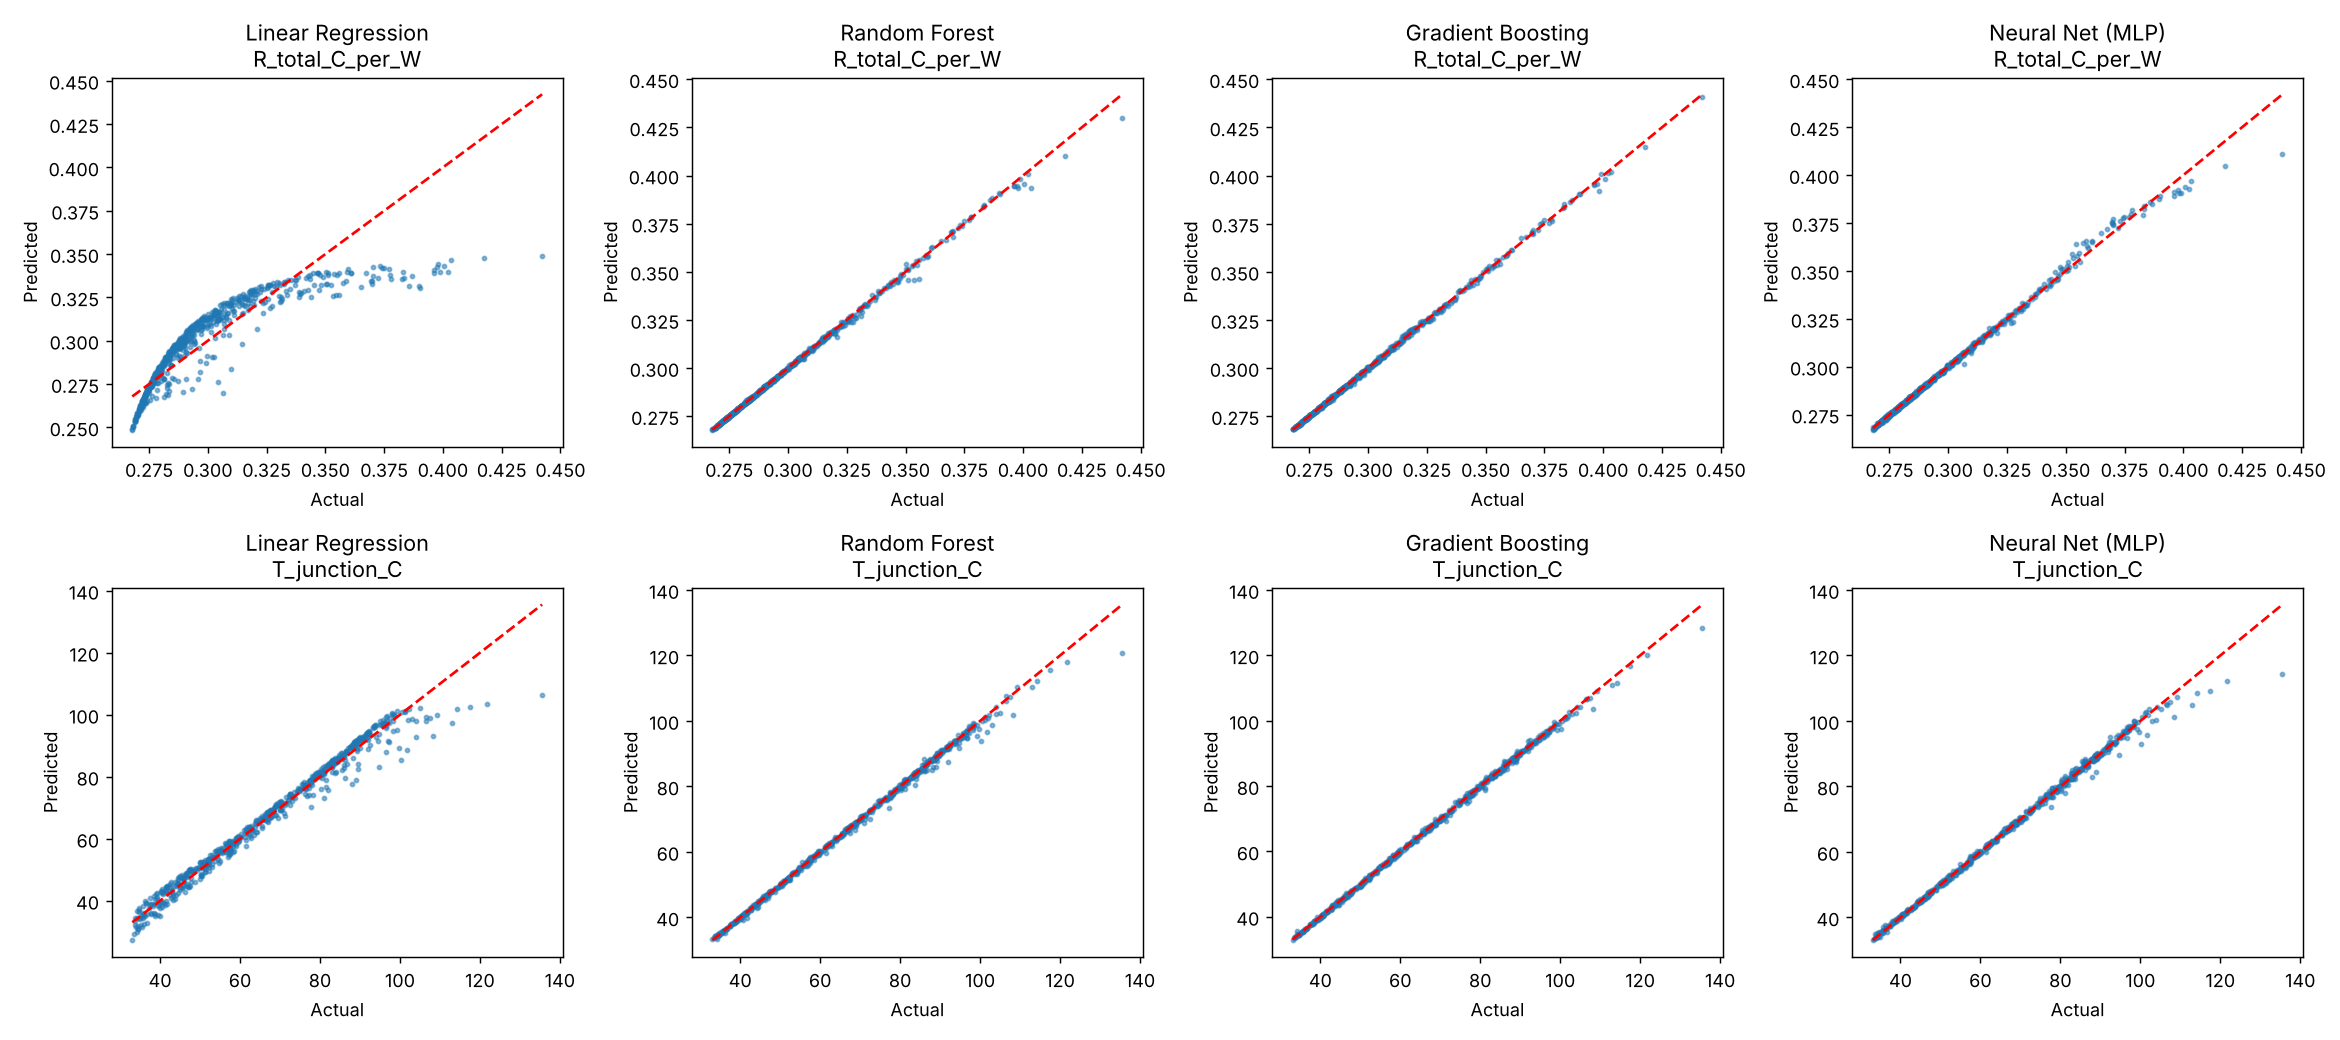

In [3]:
%run 02_ml_surrogate.py
from IPython.display import Image; Image('results/pred_vs_actual.png')

## 4. Correlation & sensitivity

Pearson
            R_total_C_per_W  T_junction_C
TDP_W               -0.001         0.976
V_air_mps           -0.836        -0.169
k_tim_WmK           -0.215        -0.049 

Spearman
            R_total_C_per_W  T_junction_C
TDP_W                0.005         0.982
V_air_mps           -0.911        -0.153
k_tim_WmK           -0.308        -0.049

Standardised regression coefficients
            R_total_C_per_W  T_junction_C
TDP_W               -0.006         0.975
V_air_mps           -0.836        -0.166
k_tim_WmK           -0.217        -0.040



Permutation importance (normalised)
            R_total_C_per_W  T_junction_C
TDP_W                0.000         0.955
V_air_mps            0.926         0.042
k_tim_WmK            0.074         0.002

Elasticities at nominal point
            Elasticity_R  Elasticity_Tj
Parameter                             
TDP_W            0.0000         0.6890
V_air_mps       -0.1432        -0.0987
k_tim_WmK       -0.0287        -0.0197


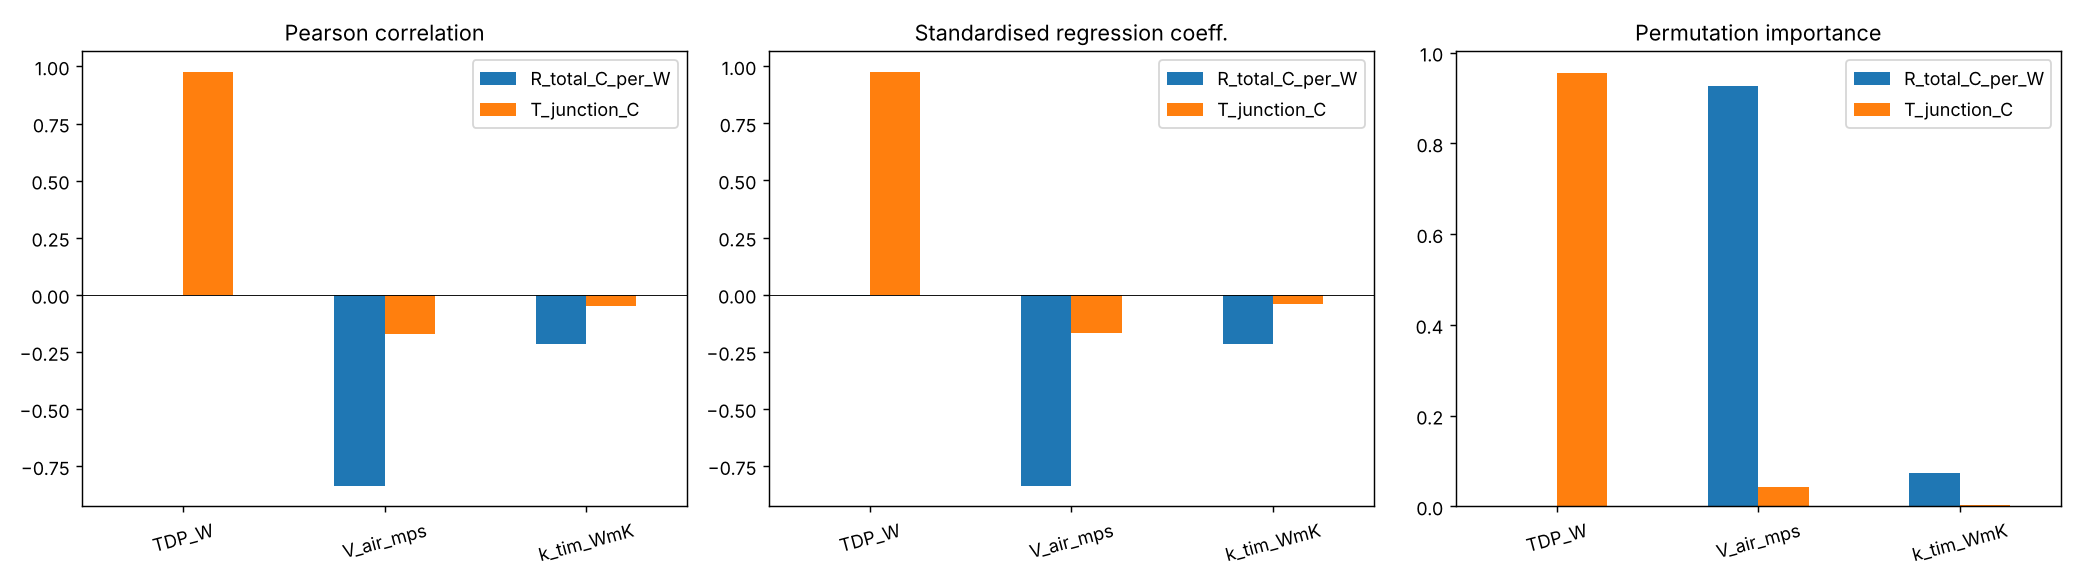

In [4]:
%run 03_sensitivity.py
Image('results/sensitivity.png')

## 5. Tuning, fresh-data and extrapolation validation

In [5]:
%run 04_validation_and_tuning.py

R_total_C_per_W best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 400} CV R2 = 0.99891


T_junction_C best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400} CV R2 = 0.99917
        Test          Target    Model     MAE    RMSE      R2
fresh points R_total_C_per_W GB tuned 0.00048 0.00070 0.99936
fresh points    T_junction_C GB tuned 0.31219 0.43385 0.99950


             Test          Target                     Model     MAE    RMSE       R2
extrapolation V>8 R_total_C_per_W             Random Forest 0.00934 0.01031 -0.44232
extrapolation V>8 R_total_C_per_W         Gradient Boosting 0.00886 0.00985 -0.31779
extrapolation V>8 R_total_C_per_W Linear + physics features 0.00000 0.00000  1.00000
extrapolation V>8    T_junction_C             Random Forest 1.73359 2.03054  0.98725
extrapolation V>8    T_junction_C         Gradient Boosting 1.34889 1.64489  0.99163
extrapolation V>8    T_junction_C Linear + physics features 2.04394 2.43028  0.98174


## 6. Inverse design (airflow needed for Tj ≤ 85 °C)

k_tim= 1: feasible up to ~195 W at 15 m/s for Tj<=85.0 C
k_tim= 4: feasible up to ~215 W at 15 m/s for Tj<=85.0 C
k_tim= 8: feasible up to ~220 W at 15 m/s for Tj<=85.0 C
k_tim=12: feasible up to ~220 W at 15 m/s for Tj<=85.0 C


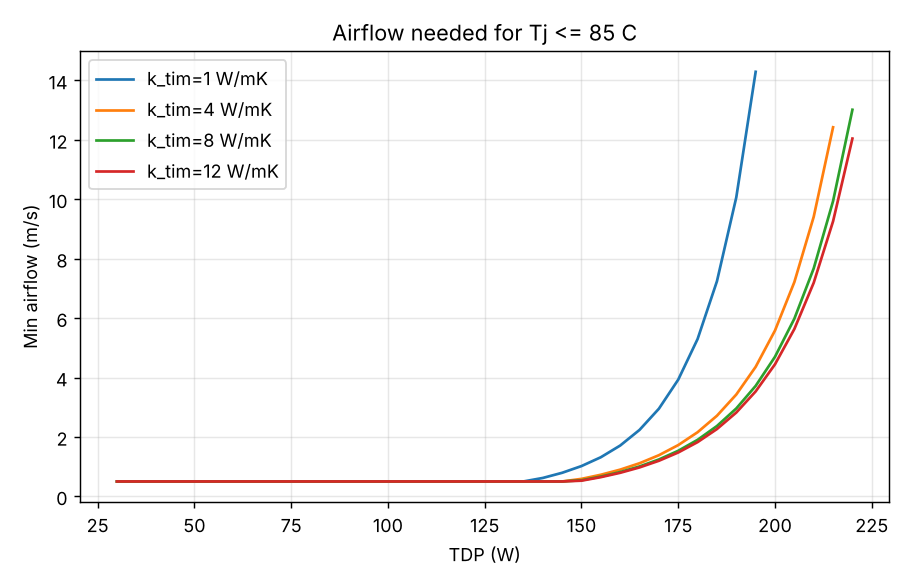

In [6]:
%run 05_inverse_design.py
Image('results/inverse_design.png')

## 7. My observations
_Write your own conclusions here._